<a href="https://colab.research.google.com/github/Jyotisrj/sql-sales-data-analysis-/blob/main/01_python_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E-commerce Delivery & Logistics Performance Analysis

**Role:** Python Analysis

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

**Dataset:** Brazilian E-Commerce (Olist)

## Objectives

* Analyse order and delivery performance.
* Calculate average delivery time and on-time/late delivery rates.
* Identify monthly order trends and order status distribution.
* Analyse freight costs and state-wise delivery performance.
* Export summary tables and charts for the Power BI dashboard.


In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import os
import zipfile

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Python analysis environment is ready!")

Python analysis environment is ready!


In [81]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [82]:
DATA_DIR = Path(
    "/content/drive/MyDrive/Ecommerce_Project/olist_cleaned_data_updated"
)

print("Folder exists:", DATA_DIR.exists())

if DATA_DIR.exists():
    print("Files in folder:")
    for file in DATA_DIR.glob("*.csv"):
        print(file.name)

Folder exists: True
Files in folder:
olist_customers_dataset.csv
olist_order_items_dataset.csv
olist_orders_dataset.csv
olist_sellers_dataset.csv


In [83]:
orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv")
order_items = pd.read_csv(DATA_DIR / "olist_order_items_dataset.csv")
customers = pd.read_csv(DATA_DIR / "olist_customers_dataset.csv")
sellers = pd.read_csv(DATA_DIR / "olist_sellers_dataset.csv")

print("Datasets loaded successfully!")

print("Orders:", orders.shape)
print("Order items:", order_items.shape)
print("Customers:", customers.shape)
print("Sellers:", sellers.shape)

Datasets loaded successfully!
Orders: (99441, 8)
Order items: (112650, 7)
Customers: (99441, 5)
Sellers: (3095, 4)


In [84]:
datasets = {
    "Orders": orders,
    "Order Items": order_items,
    "Customers": customers,
    "Sellers": sellers
}

for name, data in datasets.items():
    print(f"\n--- {name} ---")
    print("Rows and columns:", data.shape)
    print("Duplicate rows:", data.duplicated().sum())
    print("Missing values:\n", data.isnull().sum())
    print("Columns:", data.columns.tolist())


--- Orders ---
Rows and columns: (99441, 8)
Duplicate rows: 0
Missing values:
 order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
Columns: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

--- Order Items ---
Rows and columns: (112650, 7)
Duplicate rows: 0
Missing values:
 order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64
Columns: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

--- Customers

In [85]:

# KPI preparation: convert date columns

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

print("Date columns converted successfully.")
print("Orders dataset shape:", orders.shape)


Date columns converted successfully.
Orders dataset shape: (99441, 8)


In [86]:
# Calculate total orders
total_orders = orders["order_id"].nunique()

print("Total unique orders:", total_orders)

Total unique orders: 99441


In [87]:
# Analyze order status
status_summary = (
    orders.groupby("order_status")["order_id"]
    .nunique()
    .reset_index(name="total_orders")
)

status_summary["percentage"] = (
    status_summary["total_orders"] / total_orders * 100
).round(2)

status_summary = status_summary.sort_values(
    "total_orders", ascending=False
)

display(status_summary)

,order_status,total_orders,percentage
3,delivered,96478,97.02
6,shipped,1107,1.11
1,canceled,625,0.63
7,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
2,created,5,0.01
0,approved,2,0.00


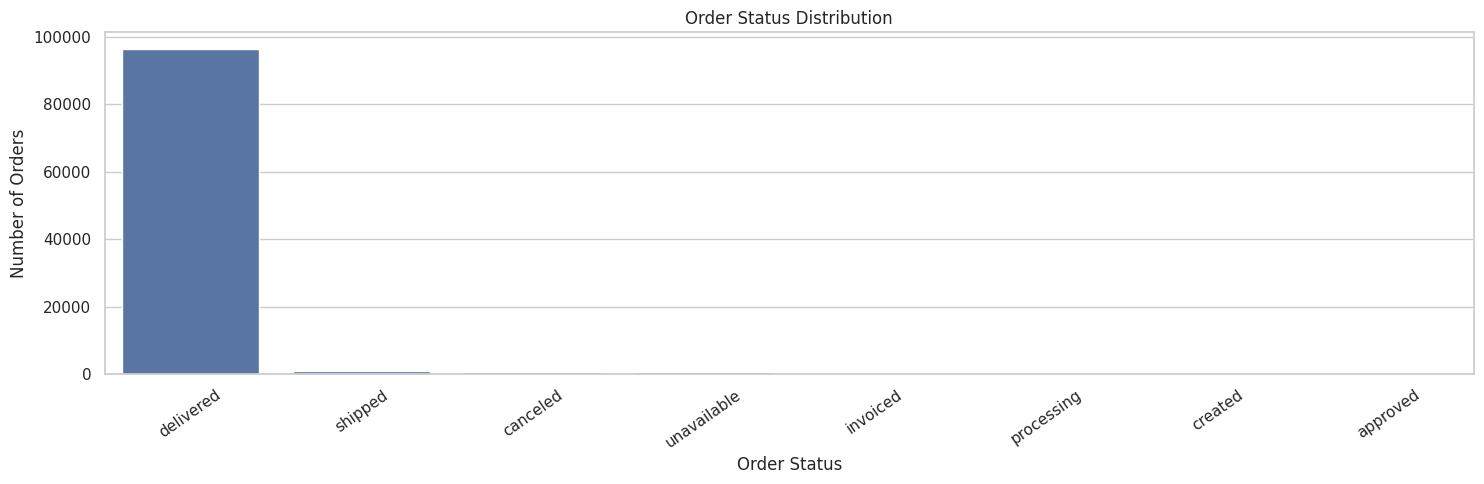

In [88]:
# Visualize the results
plt.figure(figsize=(15, 5))

sns.barplot(
    data=status_summary,
    x="order_status",
    y="total_orders"
)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=35)
plt.tight_layout()
plt.savefig(
    "order_status_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

**Order Cancellation Rate**

Formula:

*Cancellation* *Rate* =
*Number* *of* *Cancelled* *Orders* / *Total* *Orders* * *100*

In [89]:
# KPI: Order Cancellation Rate

# Count total unique orders
total_orders = orders["order_id"].nunique()

# Count unique cancelled orders
cancelled_orders = orders.loc[
    orders["order_status"] == "canceled",
    "order_id"
].nunique()

# Calculate cancellation rate
cancellation_rate = (
    cancelled_orders / total_orders * 100
    if total_orders > 0 else 0
)

print("KPI 6 — Order Cancellation Rate")
print("Total Orders:", total_orders)
print("Cancelled Orders:", cancelled_orders)
print("Cancellation Rate:", round(cancellation_rate, 2), "%")


KPI 6 — Order Cancellation Rate
Total Orders: 99441
Cancelled Orders: 625
Cancellation Rate: 0.63 %


**Calculate average delivery duration**

**Definition:** Average number of days from order placement to actual customer delivery.

We include only delivered orders that have both the purchase timestamp and actual delivery timestamp.

In [90]:
# KPI 1: Average delivery time

delivered = orders[
    (orders["order_status"] == "delivered")
    & orders["order_purchase_timestamp"].notna()
    & orders["order_delivered_customer_date"].notna()
].copy()

delivered["delivery_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Flag impossible negative delivery durations for investigation
invalid_duration_count = (delivered["delivery_days"] < 0).sum()

# Exclude negative durations from the average
valid_delivery = delivered[delivered["delivery_days"] >= 0].copy()

average_delivery_days = valid_delivery["delivery_days"].mean()

print("KPI — Average Delivery Duration")
print("Delivered orders with both dates:", len(delivered))
print("Negative durations to investigate:", invalid_duration_count)
print("Orders included in average:", len(valid_delivery))
print("Average delivery Duration:", round(average_delivery_days, 2), "days")


KPI — Average Delivery Duration
Delivered orders with both dates: 96470
Negative durations to investigate: 0
Orders included in average: 96470
Average delivery Duration: 12.56 days


**Calculate On-Time Delivery Rate**

An order is on time if its actual delivery timestamp is on or before the estimated delivery timestamp.

Formula: On-time delivered orders ÷ eligible delivered orders × 100.

In [91]:
# KPI: On-Time Delivery Rate

# Keep delivered orders with valid actual and estimated delivery dates
delivery_data = orders[
    (orders["order_status"] == "delivered")
    & orders["order_delivered_customer_date"].notna()
    & orders["order_estimated_delivery_date"].notna()
].copy()

# Identify on-time deliveries
delivery_data["is_on_time"] = (
    delivery_data["order_delivered_customer_date"]
    <= delivery_data["order_estimated_delivery_date"]
)

# Calculate on-time delivery rate
total_evaluated_orders = len(delivery_data)
on_time_orders = delivery_data["is_on_time"].sum()

on_time_delivery_rate = (
    (on_time_orders / total_evaluated_orders) * 100
    if total_evaluated_orders > 0 else 0
)

print("KPI — On-Time Delivery Rate")
print("Delivered orders evaluated:", total_evaluated_orders)
print("On-time orders:", int(on_time_orders))
print("Late orders:", total_evaluated_orders - on_time_orders)
print("On-time delivery rate:", round(on_time_delivery_rate, 2), "%")


KPI — On-Time Delivery Rate
Delivered orders evaluated: 96470
On-time orders: 88644
Late orders: 7826
On-time delivery rate: 91.89 %


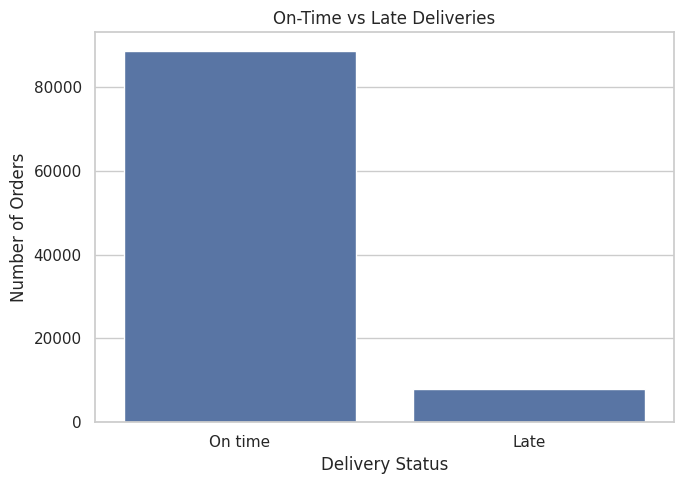

In [92]:
delivery_status_summary = pd.DataFrame({
    "Delivery status": ["On time", "Late"],
    "Orders": [
        on_time_orders,
        total_evaluated_orders - on_time_orders
    ]
})

plt.figure(figsize=(7, 5))

sns.barplot(
    data=delivery_status_summary,
    x="Delivery status",
    y="Orders"
)

plt.title("On-Time vs Late Deliveries")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.savefig(
    "On-Time vs Late Deliveries.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

**Calculate average delivery delay**

Calculate the average difference between actual and estimated delivery dates for all eligible delivered orders, including orders delivered early.
- Positive result = delivered late on average.
- Negative result = delivered early on average.
- Zero = actual and estimated dates match on average.


In [93]:
delay_data = orders[
    orders["order_status"].eq("delivered")
    & orders["order_purchase_timestamp"].notna()
    & orders["order_delivered_customer_date"].notna()
    & orders["order_estimated_delivery_date"].notna()
].copy()

# Exclude invalid negative delivery durations
delay_data = delay_data[
    delay_data["order_delivered_customer_date"]
    >= delay_data["order_purchase_timestamp"]
].copy()

delay_data["delay_days"] = (
    delay_data["order_delivered_customer_date"]
    - delay_data["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

average_delay_days = delay_data["delay_days"].mean()

print("Eligible orders for delay calculation:", len(delay_data))
print("Average delay:", round(average_delay_days, 2), "days")

Eligible orders for delay calculation: 96470
Average delay: -11.18 days


**Average delay among late deliveries only**

This is a separate diagnostic KPI. It measures how late orders were, without early deliveries reducing the average.

In [94]:
late_delivery_data = delay_data[
    delay_data["delay_days"] > 0
].copy()

average_late_delay = late_delivery_data["delay_days"].mean()

print("Late orders with valid dates:", len(late_delivery_data))
print(
    "Average delay among late orders:",
    round(average_late_delay, 2),
    "days"
)

Late orders with valid dates: 7826
Average delay among late orders: 9.55 days


**Calculate order processing time**

Definition: Order processing time is the time taken between when a customer places an order and when the order is handed over to the carrier for shipment.

**Formula:**

Purchase-to-carrier time = Order carrier handover timestamp - Order purchase timestamp.

In [95]:
processing_data = orders[
    orders["order_purchase_timestamp"].notna()
    & orders["order_delivered_carrier_date"].notna()
].copy()

processing_data["processing_hours"] = (
    processing_data["order_delivered_carrier_date"]
    - processing_data["order_purchase_timestamp"]
).dt.total_seconds() / 3600

negative_processing_count = (
    processing_data["processing_hours"] < 0
).sum()

valid_processing = processing_data[
    processing_data["processing_hours"] >= 0
].copy()

average_processing_hours = valid_processing["processing_hours"].mean()

print("Orders with both timestamps:", len(processing_data))
print("Negative durations excluded:", negative_processing_count)
print("Orders included:", len(valid_processing))
print(
    "Average purchase-to-carrier time:",
    round(average_processing_hours, 2),
    "hours"
)

Orders with both timestamps: 97658
Negative durations excluded: 166
Orders included: 97492
Average purchase-to-carrier time: 77.79 hours


In [96]:
# Keep the two processing measurements separate

average_purchase_to_carrier_hours = valid_processing[
    "processing_hours"
].mean()

# Recalculate purchase-to-approval separately
approval_data = orders[
    orders["order_purchase_timestamp"].notna()
    & orders["order_approved_at"].notna()
].copy()

approval_data["approval_hours"] = (
    approval_data["order_approved_at"]
    - approval_data["order_purchase_timestamp"]
).dt.total_seconds() / 3600

approval_data = approval_data[
    approval_data["approval_hours"] >= 0
].copy()

average_purchase_to_approval_hours = approval_data[
    "approval_hours"
].mean()

print(
    "Average purchase-to-carrier time:",
    round(average_purchase_to_carrier_hours, 2),
    "hours"
)

print(
    "Average purchase-to-approval time:",
    round(average_purchase_to_approval_hours, 2),
    "hours"
)

Average purchase-to-carrier time: 77.79 hours
Average purchase-to-approval time: 10.42 hours


**Analyze monthly order trends**

This counts unique orders by the month in which customers placed them, including all order statuses.

In [97]:
monthly_orders = orders[
    orders["order_purchase_timestamp"].notna()
].copy()

monthly_orders["order_month"] = (
    monthly_orders["order_purchase_timestamp"].dt.to_period("M")
)

monthly_orders = (
    monthly_orders.groupby("order_month")["order_id"]
    .nunique()
    .reset_index(name="total_orders")
)

monthly_orders["order_month"] = (
    monthly_orders["order_month"].astype(str)
)

display(monthly_orders.head(10))

,order_month,total_orders
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


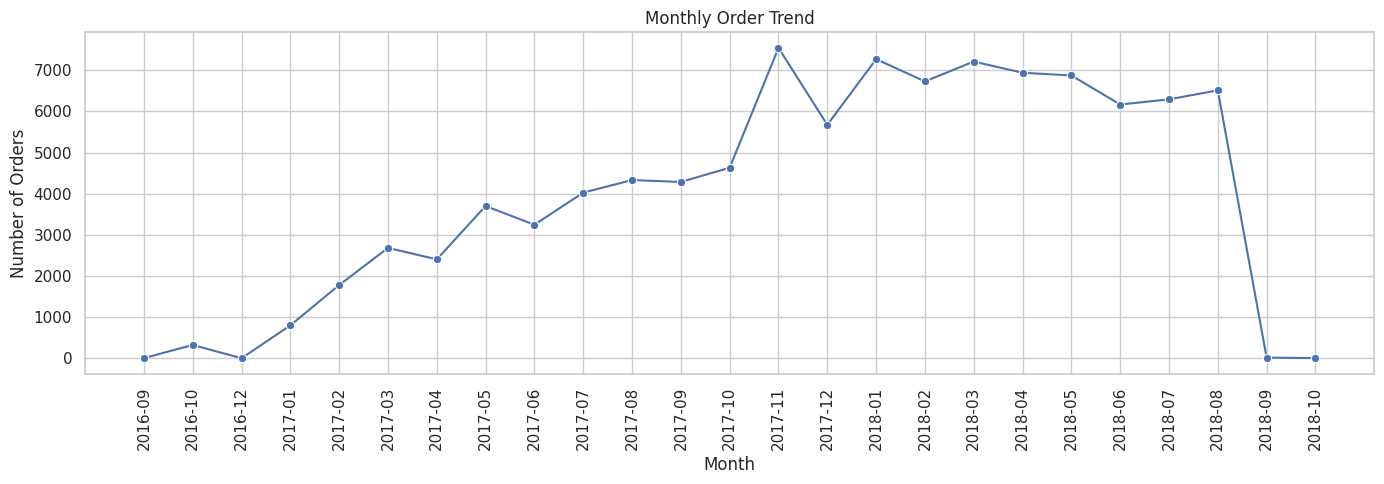

In [98]:
# Visualize the monthly trend:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_orders,
    x="order_month",
    y="total_orders",
    marker="o"
)

plt.title("Monthly Order Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(
    "monthly_order_trend.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

**Calculate freight costs**

An order can contain multiple items. Therefore, first sum freight charges for each order, then calculate the average freight per order.

In [99]:
print("Order item columns:", order_items.columns.tolist())

Order item columns: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']


In [100]:
freight_per_order = (
    order_items.groupby("order_id")["freight_value"]
    .sum(min_count=1)
    .reset_index(name="total_freight")
)

total_freight_cost = freight_per_order["total_freight"].sum(
    min_count=1
)

average_freight_per_order = freight_per_order[
    "total_freight"
].mean()

median_freight_per_order = freight_per_order[
    "total_freight"
].median()

print("Orders with item freight data:", len(freight_per_order))
print("Total freight cost:", round(total_freight_cost, 2))
print("Average freight per order:", round(average_freight_per_order, 2))
print("Median freight per order:", round(median_freight_per_order, 2))
print("Currency: Brazilian real (BRL)")

Orders with item freight data: 98666
Total freight cost: 2251909.54
Average freight per order: 22.82
Median freight per order: 17.17
Currency: Brazilian real (BRL)


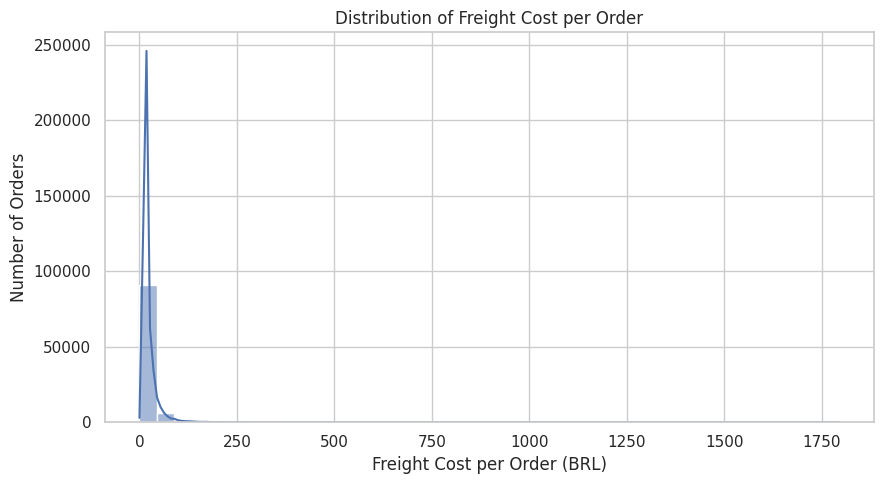

In [101]:
# Visualize the distribution:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=freight_per_order,
    x="total_freight",
    bins=40,
    kde=True
)

plt.title("Distribution of Freight Cost per Order")
plt.xlabel("Freight Cost per Order (BRL)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.savefig(
    "freight_cost_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

**Prepare regional performance data**

We can compare regions using customer_state. This does not measure carrier performance; it measures the performance of orders associated with customers in each state.

In [102]:
regional_orders = orders.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Regional dataset shape:", regional_orders.shape)
print("Missing customer states:", regional_orders["customer_state"].isna().sum())

display(regional_orders.head())

Regional dataset shape: (99441, 9)
Missing customer states: 0


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,SP


In [103]:
# Calculate orders and cancellation rate by state
regional_summary = (
    regional_orders.groupby("customer_state")
    .agg(
        total_orders=("order_id", "nunique"),
        cancelled_orders=(
            "order_id",
            lambda x: x[
                regional_orders.loc[x.index, "order_status"].eq("canceled")
            ].nunique()
        )
    )
    .reset_index()
)

regional_summary["cancellation_rate_pct"] = (
    regional_summary["cancelled_orders"]
    / regional_summary["total_orders"] * 100
).round(2)

regional_summary = regional_summary.sort_values(
    "total_orders", ascending=False
)

display(regional_summary)

,customer_state,total_orders,cancelled_orders,cancellation_rate_pct
25,SP,41746,327,0.78
18,RJ,12852,86,0.67
10,MG,11635,64,0.55
22,RS,5466,25,0.46
17,PR,5045,22,0.44
23,SC,3637,19,0.52
4,BA,3380,16,0.47
6,DF,2140,7,0.33
7,ES,2033,9,0.44
8,GO,2020,13,0.64


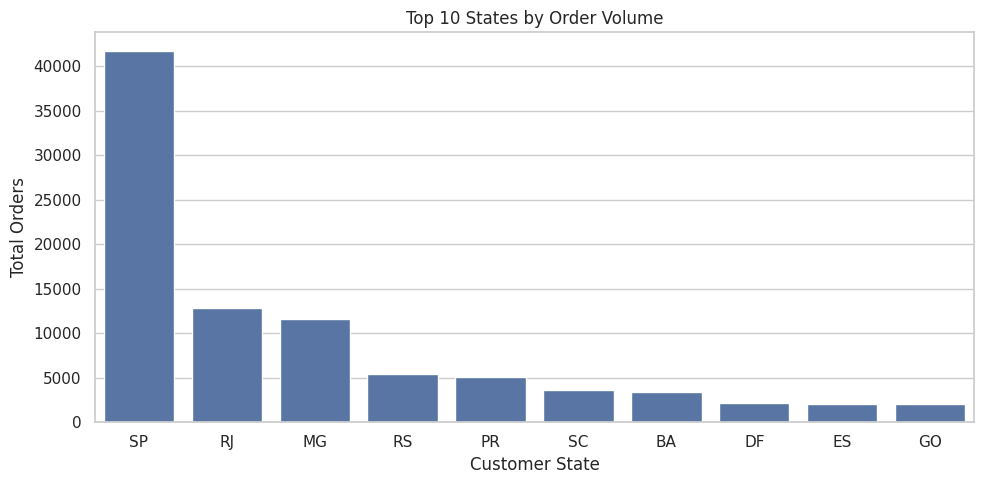

In [104]:
# Visualize the states with the highest order volume:
top_states = regional_summary.head(10)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_states,
    x="customer_state",
    y="total_orders"
)

plt.title("Top 10 States by Order Volume")
plt.xlabel("Customer State")
plt.ylabel("Total Orders")
plt.tight_layout()
plt.savefig(
    "top_states_by_order_volume.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [105]:
# Calculate delivery duration by state
regional_delivery = regional_orders[
    regional_orders["order_status"].eq("delivered")
    & regional_orders["order_purchase_timestamp"].notna()
    & regional_orders["order_delivered_customer_date"].notna()
].copy()

regional_delivery["delivery_days"] = (
    regional_delivery["order_delivered_customer_date"]
    - regional_delivery["order_purchase_timestamp"]
).dt.total_seconds() / 86400

regional_delivery = regional_delivery[
    regional_delivery["delivery_days"] >= 0
]

regional_delivery_summary = (
    regional_delivery.groupby("customer_state")
    .agg(
        delivered_orders=("order_id", "nunique"),
        average_delivery_days=("delivery_days", "mean")
    )
    .reset_index()
)

regional_delivery_summary["average_delivery_days"] = (
    regional_delivery_summary["average_delivery_days"].round(2)
)

regional_delivery_summary = regional_delivery_summary.sort_values(
    "delivered_orders", ascending=False
)

display(regional_delivery_summary)

,customer_state,delivered_orders,average_delivery_days
25,SP,40494,8.76
18,RJ,12350,15.31
10,MG,11354,12.01
22,RS,5344,15.30
17,PR,4923,11.99
23,SC,3546,14.95
4,BA,3256,19.34
6,DF,2080,12.97
7,ES,1995,15.79
8,GO,1957,15.61


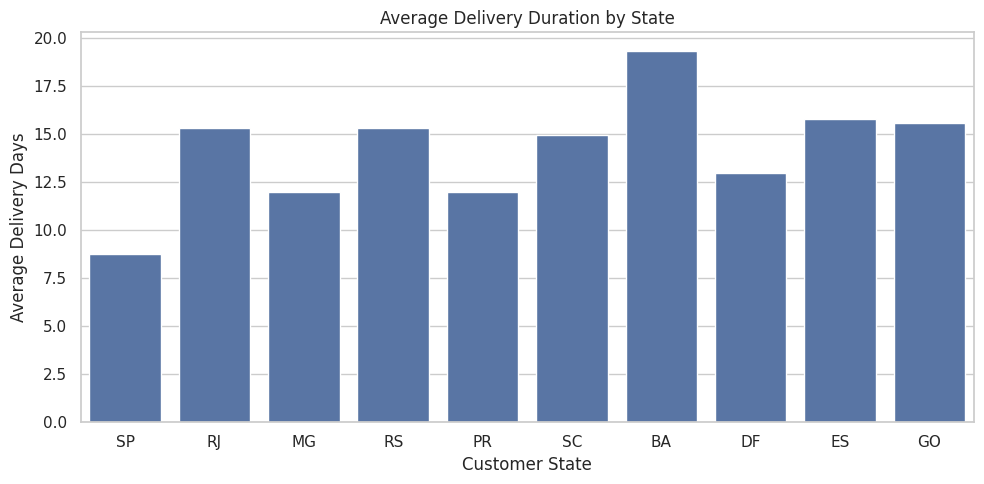

In [106]:
# Visualize the 10 states with the most delivered orders evaluated:
top_delivery_states = regional_delivery_summary.head(10)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_delivery_states,
    x="customer_state",
    y="average_delivery_days"
)

plt.title("Average Delivery Duration by State")
plt.xlabel("Customer State")
plt.ylabel("Average Delivery Days")
plt.tight_layout()
plt.savefig(
    "average_delivery_duration_by_state.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [107]:
# Calculate on-time rate by state
regional_on_time = regional_orders[
    regional_orders["order_status"].eq("delivered")
    & regional_orders["order_purchase_timestamp"].notna()
    & regional_orders["order_delivered_customer_date"].notna()
    & regional_orders["order_estimated_delivery_date"].notna()
].copy()

regional_on_time = regional_on_time[
    regional_on_time["order_delivered_customer_date"]
    >= regional_on_time["order_purchase_timestamp"]
].copy()

regional_on_time["is_on_time"] = (
    regional_on_time["order_delivered_customer_date"]
    <= regional_on_time["order_estimated_delivery_date"]
)

regional_on_time_summary = (
    regional_on_time.groupby("customer_state")
    .agg(
        eligible_orders=("order_id", "nunique"),
        on_time_orders=(
            "order_id",
            lambda x: x[
                regional_on_time.loc[x.index, "is_on_time"]
            ].nunique()
        )
    )
    .reset_index()
)

regional_on_time_summary["on_time_rate_pct"] = (
    regional_on_time_summary["on_time_orders"]
    / regional_on_time_summary["eligible_orders"] * 100
).round(2)

regional_on_time_summary = regional_on_time_summary.sort_values(
    "eligible_orders", ascending=False
)

display(regional_on_time_summary)

,customer_state,eligible_orders,on_time_orders,on_time_rate_pct
25,SP,40494,38107,94.11
18,RJ,12350,10686,86.53
10,MG,11354,10717,94.39
22,RS,5344,4962,92.85
17,PR,4923,4677,95.00
23,SC,3546,3200,90.24
4,BA,3256,2799,85.96
6,DF,2080,1933,92.93
7,ES,1995,1751,87.77
8,GO,1957,1797,91.82


In [108]:
# Final KPI Summary

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total unique orders",
        "Cancelled orders",
        "Cancellation rate (%)",
        "Average delivery duration (days)",
        "Eligible delivered orders for on-time calculation",
        "On-time orders",
        "Late orders",
        "On-time delivery rate (%)",
        "Average actual minus estimated delivery (days)",
        "Average delay among late deliveries (days)",
        "Average purchase-to-carrier time (hours)",
        "Average purchase-to-approval time (hours)",
        "Total freight cost (BRL)",
        "Average freight per order (BRL)",
        "Median freight per order (BRL)"
    ],
    "Value": [
        total_orders,
        cancelled_orders,
        round(cancellation_rate, 2),
        round(average_delivery_days, 2),
        total_evaluated_orders,
        int(on_time_orders),
        int(total_evaluated_orders - on_time_orders),
        round(on_time_delivery_rate, 2),
        round(average_delay_days, 2),
        round(average_late_delay, 2),
        round(average_purchase_to_carrier_hours, 2),
        round(average_purchase_to_approval_hours, 2),
        round(total_freight_cost, 2),
        round(average_freight_per_order, 2),
        round(median_freight_per_order, 2)
    ]
})

display(kpi_summary)

,KPI,Value
0,Total unique orders,99441.00
1,Cancelled orders,625.00
2,Cancellation rate (%),0.63
3,Average delivery duration (days),12.56
4,Eligible delivered orders for on-time calculation,96470.00
5,On-time orders,88644.00
6,Late orders,7826.00
7,On-time delivery rate (%),91.89
8,Average actual minus estimated delivery (days),-11.18
9,Average delay among late deliveries (days),9.55


In [109]:
kpi_summary.to_csv("kpi_summary.csv", index=False)
status_summary.to_csv("order_status_summary.csv", index=False)
monthly_orders.to_csv("monthly_order_trends.csv", index=False)
regional_summary.to_csv("regional_cancellation_summary.csv", index=False)
regional_delivery_summary.to_csv("regional_delivery_summary.csv", index=False)
regional_on_time_summary.to_csv("regional_on_time_summary.csv", index=False)

print("KPI summary files exported successfully.")

KPI summary files exported successfully.


## Conclusion

The analysis examined order status, cancellations, delivery duration, delivery delays, processing-time indicators, monthly order trends, freight costs, and state-wise delivery performance using the Brazilian E-Commerce (Olist) dataset.

The dataset contains 99,441 unique orders. The calculated cancellation rate is 0.63%, and the on-time delivery rate is 91.89% among eligible delivered orders. The average delivery duration is 12.56 days. The average difference between actual and estimated delivery dates is -11.18 days, indicating that deliveries occurred earlier than estimated on average. Among late deliveries, the average delay is 9.55 days.

The average purchase-to-carrier handover time is 77.79 hours, while the average purchase-to-approval time is 10.42 hours. These are separate measurements and should not be interpreted as the same processing stage. The average freight cost per order with available item data is 22.82 BRL.

The findings provide a starting point for identifying delivery-performance patterns and comparing customer states. Further validation and additional datasets may be needed for customer-rating, product-category, and carrier-specific analysis. These results describe observed patterns and do not, by themselves, establish the causes of delivery delays.